# 10 — A single Bayesian model: region, time drift, preconditioning and bursts

Notebooks 08–09 found, one at a time, that the nucleus–cytoplasm difference $\Delta$ can be affected by (i) a **temporal drift** (regions measured in separate time blocks), (ii) **preconditioning** (later curves at a spot are softer, and the nucleus has longer bursts) and (iii) **dependence between curves of the same burst**. This notebook puts all three in **one hierarchical model** and reads $\Delta$ from its posterior.

For a curve $i$ of burst $b$, region $r$ (0 cytoplasm, 1 nucleus), time $t$ (in units of 10 min, centred) and position $p$ in the burst:
$$y_i=a+\beta\,r_i+\gamma\,t_i+\delta_{p_i}+u_b+\varepsilon_i,\qquad u_b\sim\mathcal N(0,\tau^2),\ \ \varepsilon_i\sim\mathcal N(0,\sigma_{r}^2),$$
with $\beta$ the nucleus–cytoplasm difference **at a common time and for the same position in the burst**, $\gamma$ the drift, $\delta_p$ the position effects (1st curve as reference). The burst effect $u_b$ is integrated out analytically; the posterior is sampled with `emcee`, per line, for $y=\log A$, $\log F(300\,\mathrm{nm})$ and the free exponent. Four models are compared: M0 (region only), M1 (+ drift), M2 (+ position), M3 (all).

**What this notebook does**

- samples the four models and compares them with the cluster-level WAIC;
- reports the posterior of $\beta$ for each model and observable;
- shows how the conclusion depends on the **prior on the drift** $\gamma$: the drift and the region effect are only weakly separated by the design, so how large a drift one is willing to believe matters.

**What it does NOT do**

- it does not identify the cell: bursts are a proxy for the spot;
- it cannot identify $\gamma$ and $\beta$ independently with more than the within-block information (the blocks do not overlap in time);
- it does not model the line difference (calibration differs between sessions, notebook 09): each line is fitted separately.

All variables are standardised per line (standard-deviation units) for the sampling; results are converted back to the original units.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, special
import emcee
import afm_tools as T

T.set_plot_style()
SEED = 20261016; RNG = np.random.default_rng(SEED); summary = {}; lines = ["MCF7R", "T47DR"]
fit = T.load_fit_table(); fit = fit[fit.fit_status == "ok"]
times = pd.read_csv(T.RESULTS_DIR / "acquisition_times.csv", parse_dates=["t"]); prof = pd.read_csv(T.RESULTS_DIR / "force_indentation_profiles.csv")
df = fit.merge(times, on=["file_name", "group"]).merge(prof[["file_name", "group", "F_300nm"]], on=["file_name", "group"], how="left").sort_values(["cell_line", "region", "t"]).reset_index(drop=True)
df["logF300"] = np.log(df.F_300nm.clip(lower=1e-3)); df["gap_s"] = df.groupby(["cell_line", "region"]).t.diff().dt.total_seconds()
df["burst"] = df.groupby(["cell_line", "region"], group_keys=False).apply(lambda d: ((d.gap_s.isna()) | (d.gap_s > 10)).cumsum())
df["cluster"] = df.cell_line + "_" + df.region + "_" + df.burst.astype(str); df["pos"] = df.groupby("cluster").cumcount() + 1
df["t10"] = df.groupby("cell_line").t.transform(lambda s: (s - s.min()).dt.total_seconds() / 600)      # units of 10 min
print(len(df), "curves,", df.cluster.nunique(), "bursts")

257 curves, 62 bursts


## 1. Model and sampler

`make_model` builds the log-posterior for one line and one observable. Parameters (in sd units): $a,\beta,\gamma,\delta_2,\delta_3,\delta_{4+},\ln\tau,\ln\sigma_{cyto},\ln\sigma_{nuc}$; the unused ones are fixed to zero by the model mask. Priors: $a\sim\mathcal N(0,2^2)$, $\beta\sim\mathcal N(0,1)$, $\gamma\sim\mathcal N(0,s_\gamma^2)$ (nominal $s_\gamma=0.3$ sd per 10 min), $\delta\sim\mathcal N(0,0.5^2)$, $\tau,\sigma\sim$ HalfNormal(1).

In [2]:
MODELS = {"M0 region": dict(g=0, d=0), "M1 + drift": dict(g=1, d=0), "M2 + position": dict(g=0, d=1), "M3 drift + position": dict(g=1, d=1)}

def prepare(d, col):
    d = d.dropna(subset=[col]).copy(); mu, sd = d[col].mean(), d[col].std(); y = ((d[col] - mu) / sd).to_numpy()
    b = pd.factorize(d.cluster)[0]; nb = b.max() + 1; reg_b = np.zeros(nb, int); reg_b[b] = (d.region == "nucleo").astype(int).to_numpy()
    return dict(y=y, nuc=(d.region == "nucleo").astype(float).to_numpy(), t=(d.t10 - d.t10.mean()).to_numpy(), p2=(d.pos == 2).astype(float).to_numpy(), p3=(d.pos == 3).astype(float).to_numpy(), p4=(d.pos >= 4).astype(float).to_numpy(),
                b=b, nb=nb, nobs=np.bincount(b), reg_b=reg_b, mu=mu, sd=sd, n=len(y))

def burst_loglik(th, D):
    a, beta, gam, d2, d3, d4, lt, ls0, ls1 = th; tau2 = np.exp(2 * lt); sig2 = np.exp(2 * np.where(D["reg_b"] == 1, ls1, ls0))
    r = D["y"] - (a + beta * D["nuc"] + gam * D["t"] + d2 * D["p2"] + d3 * D["p3"] + d4 * D["p4"])
    S1 = np.bincount(D["b"], r, D["nb"]); S2 = np.bincount(D["b"], r * r, D["nb"]); n = D["nobs"]; den = sig2 + n * tau2
    return -0.5 * ((S2 - tau2 / den * S1 ** 2) / sig2 + (n - 1) * np.log(sig2) + np.log(den) + n * np.log(2 * np.pi))

def make_logp(D, mask, s_gamma=0.3):
    def logp(x):
        th = np.zeros(9); th[mask] = x
        if th[6] < -5 or th[6] > 2 or th[7] < -5 or th[7] > 2 or th[8] < -5 or th[8] > 2: return -np.inf
        lp = stats.norm.logpdf(th[0], 0, 2) + stats.norm.logpdf(th[1], 0, 1) + stats.norm.logpdf(th[2], 0, s_gamma) + stats.norm.logpdf(th[3:6], 0, .5).sum()
        lp += sum(-0.5 * np.exp(2 * v) + v for v in th[6:9])          # HalfNormal(1) on tau, sigma_c, sigma_n in log space
        return lp + burst_loglik(th, D).sum()
    return logp

def run_model(D, model, s_gamma=0.3, nwalk=40, nsteps=4000, burn=1500, seed=1):
    cfg = MODELS[model]; mask = np.array([True, True, bool(cfg["g"]), bool(cfg["d"]), bool(cfg["d"]), bool(cfg["d"]), True, True, True]); k = mask.sum()
    p0 = np.zeros(9); p0[6:9] = [np.log(.3), 0, 0]; rg = np.random.default_rng(seed); start = p0[mask] + 1e-2 * rg.standard_normal((nwalk, k))
    sam = emcee.EnsembleSampler(nwalk, k, make_logp(D, mask, s_gamma)); sam.run_mcmc(start, nsteps, progress=False)
    ch = sam.get_chain()[burn:].reshape(-1, k); full = np.zeros((len(ch), 9)); full[:, mask] = ch; return full, sam.get_autocorr_time(tol=0).max()

def waic_burst(D, post, n=300):
    idx = RNG.choice(len(post), n, replace=False); ll = np.array([burst_loglik(post[i], D) for i in idx]); lppd = special.logsumexp(ll, axis=0) - np.log(n)
    return float((lppd - ll.var(0)).sum())

def summarize(v):
    return dict(median=float(np.median(v)), lo68=float(np.quantile(v, .16)), hi68=float(np.quantile(v, .84)), lo95=float(np.quantile(v, .025)), hi95=float(np.quantile(v, .975)), P_neg=float((v < 0).mean()))
print("model code ready")

model code ready


## 2. Fit the four models for three observables, per line

For each line and observable the four models are sampled; $\beta$ is converted to the original units (multiplying by the observable's standard deviation). The cluster-level WAIC (burst as the unit) compares the models.

In [3]:
OBS = [("logA", "log A"), ("logF300", "log F(300 nm)"), ("exponent_hat", "free exponent")]
res, waics, taus = {}, {}, {}
for l in lines:
    for col, lab in OBS:
        D = prepare(df[df.cell_line == l], col)
        for mdl in MODELS:
            post, tau_ac = run_model(D, mdl); res[(l, col, mdl)] = dict(beta=summarize(post[:, 1] * D["sd"]), gamma_per_10min=summarize(post[:, 2] * D["sd"]), tau_over_sigma=float(np.median(np.exp(post[:, 6]) / np.exp(post[:, 8]))), tau_ac=float(tau_ac))
            res[(l, col, mdl)]["delta2_first_to_second"] = summarize(post[:, 3] * D["sd"]); waics[(l, col, mdl)] = waic_burst(D, post)
rows = [dict(line=k[0], observable=k[1], model=k[2], beta_median=v["beta"]["median"], lo68=v["beta"]["lo68"], hi68=v["beta"]["hi68"], lo95=v["beta"]["lo95"], hi95=v["beta"]["hi95"], P_beta_neg=v["beta"]["P_neg"],
             gamma_per_10min=v["gamma_per_10min"]["median"], delta2=v["delta2_first_to_second"]["median"], elpd_waic=waics[k], autocorr=v["tau_ac"]) for k, v in res.items()]
tab = pd.DataFrame(rows); summary["models"] = tab.round(4).to_dict("records")
display(tab[tab.observable == "logA"].round(3).set_index(["line", "model"]))

observable  beta_median   lo68   hi68   lo95   hi95  \
line  model                                                                     
MCF7R M0 region                 logA       -0.790 -0.873 -0.707 -0.953 -0.622   
      M1 + drift                logA       -0.883 -1.049 -0.714 -1.207 -0.533   
      M2 + position             logA       -0.785 -0.869 -0.702 -0.949 -0.620   
      M3 drift + position       logA       -0.882 -1.047 -0.717 -1.217 -0.546   
T47DR M0 region                 logA       -0.222 -0.336 -0.106 -0.445  0.015   
      M1 + drift                logA        0.031 -0.160  0.223 -0.349  0.409   
      M2 + position             logA       -0.176 -0.290 -0.057 -0.404  0.057   
      M3 drift + position       logA        0.045 -0.147  0.236 -0.337  0.416   

                           P_beta_neg  gamma_per_10min  delta2  elpd_waic  \
line  model                                                                 
MCF7R M0 region                 1.000            0.000   0.000   -123.088   
      M1 + drift                1.000            0.036   0.000   -123.425   
      M2 + position             1.000            0.000  -0.245   -120.985   
      M3 drift + position       1.000            0.037  -0.246   -121.125   
T47DR M0 region                 0.967            0.000   0.000   -199.762   
      M1 + drift                0.433           -0.121   0.000   -199.213   
      M2 + position             0.932            0.000  -0.130   -197.737   
      M3 drift + position       0.408           -0.103  -0.131   -197.148   

                           autocorr  
line  model                          
MCF7R M0 region              67.307  
      M1 + drift             66.193  
      M2 + position          99.803  
      M3 drift + position   114.929  
T47DR M0 region              67.782  
      M1 + drift             79.795  
      M2 + position         103.175  
      M3 drift + position   120.198

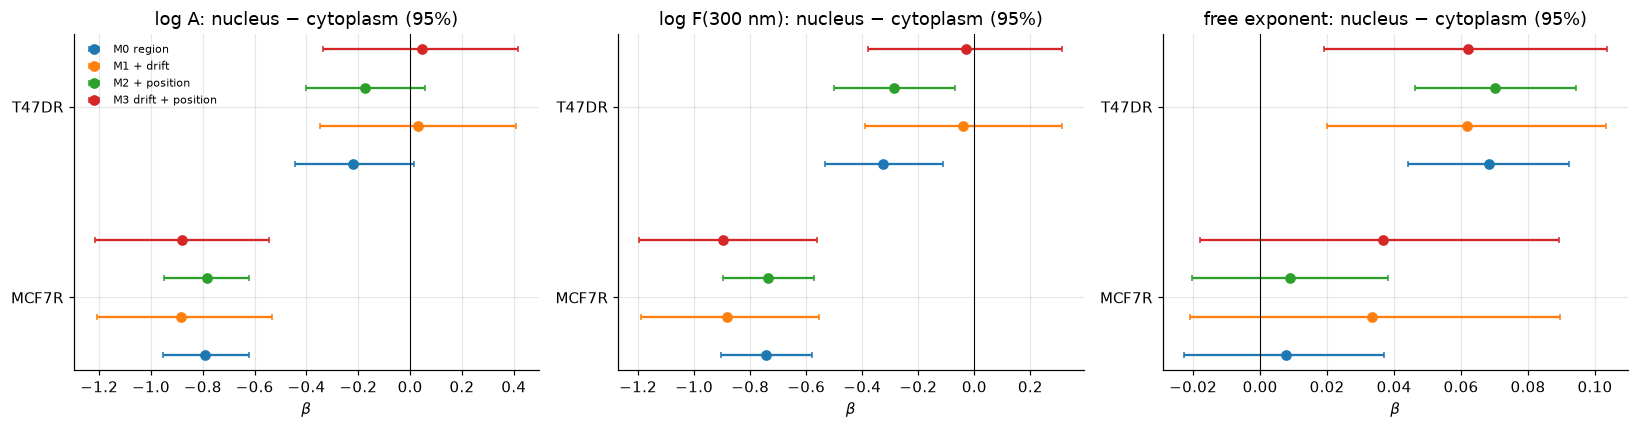

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (col, lab) in zip(ax, OBS):
    for j, l in enumerate(lines):
        t = tab[(tab.line == l) & (tab.observable == col)]
        for i, (_, r_) in enumerate(t.iterrows()):
            y = j * 5 + i; a.errorbar(r_.beta_median, y, xerr=[[r_.beta_median - r_.lo95], [r_.hi95 - r_.beta_median]], fmt="o", color=f"C{i}", capsize=2, label=r_.model if j == 0 else None)
    a.axvline(0, c="k", lw=.7); a.set_yticks([1.5, 6.5], lines); a.set_title(f"{lab}: nucleus − cytoplasm (95%)"); a.set_xlabel(r"$\beta$")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 3. Model comparison

Cluster-level WAIC (higher is better; the differences are in units of log-likelihood, with burst-level uncertainty of a few units): does the data support a drift term, a position term, or both?

In [5]:
cmp = tab.pivot_table(index=["line", "observable"], columns="model", values="elpd_waic"); cmp = cmp.sub(cmp.max(axis=1), axis=0)
summary["waic_relative_to_best"] = {f"{k[0]}|{k[1]}": v for k, v in cmp.round(2).to_dict("index").items()}; cmp.round(2)

model               M0 region  M1 + drift  M2 + position  M3 drift + position
line  observable                                                             
MCF7R exponent_hat      -5.57       -5.20           0.00                -0.55
      logA              -2.10       -2.44           0.00                -0.14
      logF300           -2.32       -1.98          -0.53                 0.00
T47DR exponent_hat      -0.99       -1.67           0.00                -1.98
      logA              -2.61       -2.06          -0.59                 0.00
      logF300           -2.28        0.00          -2.61                -1.43

## 4. How large a drift must one believe? Sensitivity to the prior on $\gamma$

Since the two regions occupy separate time blocks, the data constrain the drift only through the within-block slopes. The posterior of $\beta$ in M3 (drift + position) is recomputed for prior widths $s_\gamma$ from 0.05 to 3 sd per 10 min, for $\log A$. A very tight prior ($s_\gamma\to0$) means «no drift»; a very wide prior lets the data decide.

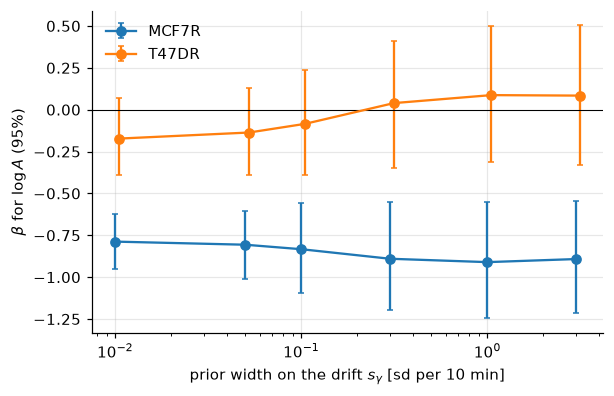

,line,s_gamma_sd_per_10min,beta_median,lo68,hi68,lo95,hi95,P_neg,gamma_median
0,MCF7R,0.01,-0.788,-0.873,-0.704,-0.954,-0.622,1.000,0.001
1,MCF7R,0.05,-0.806,-0.913,-0.705,-1.014,-0.604,1.000,0.008
2,MCF7R,0.10,-0.833,-0.969,-0.696,-1.096,-0.554,1.000,0.021
3,MCF7R,0.30,-0.890,-1.045,-0.724,-1.193,-0.549,1.000,0.041
4,MCF7R,1.00,-0.910,-1.079,-0.732,-1.243,-0.552,1.000,0.048
5,MCF7R,3.00,-0.892,-1.062,-0.722,-1.217,-0.546,1.000,0.042
6,T47DR,0.01,-0.173,-0.285,-0.052,-0.392,0.069,0.919,-0.001
7,T47DR,0.05,-0.136,-0.267,-0.007,-0.393,0.127,0.852,-0.015
8,T47DR,0.10,-0.084,-0.236,0.076,-0.390,0.234,0.702,-0.043
9,T47DR,0.30,0.039,-0.151,0.228,-0.349,0.412,0.422,-0.099


In [6]:
rows = []
for l in lines:
    D = prepare(df[df.cell_line == l], "logA")
    for sg in [0.01, 0.05, 0.1, 0.3, 1.0, 3.0]:
        post, _ = run_model(D, "M3 drift + position", s_gamma=sg, nsteps=3000, burn=1000, seed=3); s = summarize(post[:, 1] * D["sd"]); g = summarize(post[:, 2] * D["sd"])
        rows.append(dict(line=l, s_gamma_sd_per_10min=sg, beta_median=s["median"], lo68=s["lo68"], hi68=s["hi68"], lo95=s["lo95"], hi95=s["hi95"], P_neg=s["P_neg"], gamma_median=g["median"]))
sens = pd.DataFrame(rows); summary["drift_prior_sensitivity"] = sens.round(4).to_dict("records")
fig, ax = plt.subplots(figsize=(6, 3.8))
for j, l in enumerate(lines):
    t = sens[sens.line == l]; ax.errorbar(t.s_gamma_sd_per_10min * (1 + .05 * j), t.beta_median, [t.beta_median - t.lo95, t.hi95 - t.beta_median], marker="o", capsize=2, label=l)
ax.axhline(0, c="k", lw=.7); ax.set_xscale("log"); ax.set_xlabel(r"prior width on the drift $s_\gamma$ [sd per 10 min]"); ax.set_ylabel(r"$\beta$ for $\log A$ (95%)"); ax.legend(); plt.show(); sens.round(3)

## 5. Do the two lines have the same effect?

Posterior of $\beta_{MCF7R}-\beta_{T47DR}$ in M3 (draws of the two lines are independent). Each $\beta$ is a within-session difference, so a calibration error of the spring constant (notebook 09) cancels in it and also in this contrast; what remains is the confounding of cell line with session (day, cells, preparation).

In [7]:
D1, D2 = prepare(df[df.cell_line == "MCF7R"], "logA"), prepare(df[df.cell_line == "T47DR"], "logA")
p1, _ = run_model(D1, "M3 drift + position", seed=5); p2, _ = run_model(D2, "M3 drift + position", seed=6)
n = min(len(p1), len(p2)); b1 = RNG.choice(p1[:, 1] * D1["sd"], n); b2 = RNG.choice(p2[:, 1] * D2["sd"], n); diff = b1 - b2
summary["interaction_M3_logA"] = summarize(diff); summary["interaction_M3_logA"]["beta_MCF7R"] = summarize(b1); summary["interaction_M3_logA"]["beta_T47DR"] = summarize(b2)
print("beta_MCF7R - beta_T47DR:", {k: round(v, 3) for k, v in summarize(diff).items()}); print("beta_T47DR:", {k: round(v, 3) for k, v in summarize(b2).items()})
json.dump(summary, open(T.RESULTS_DIR / "10_summary.json", "w"), indent=1, default=float)

beta_MCF7R - beta_T47DR: {'median': -0.933, 'lo68': -1.182, 'hi68': -0.681, 'lo95': -1.425, 'hi95': -0.427, 'P_neg': 1.0}
beta_T47DR: {'median': 0.049, 'lo68': -0.143, 'hi68': 0.237, 'lo95': -0.344, 'hi95': 0.422, 'P_neg': 0.4}


## Interpretation and limits

- **MCF7R.** The nucleus is softer than the cytoplasm in every model: $\beta=-0.79$ (region only) and $-0.88$ with drift and position effects, 95% interval $[-1.22,-0.55]$ for $\log A$, posterior probability of a negative $\beta$ equal to 1.00, and the same for $\log F(300\,\mathrm{nm})$. The conclusion does not depend on the width of the prior on the drift ($\beta$ between $-0.79$ and $-0.91$ for $s_\gamma$ from 0.01 to 3). The drift is positive (small), i.e. it works against the effect.
- **T47DR, stiffness.** With the burst structure alone the posterior is already weak: $\beta=-0.22$, 95% interval $[-0.45,+0.02]$, $P(\beta<0)=0.97$. Adding the drift moves it to $+0.03$ $[-0.35,+0.41]$ ($P=0.43$); the data estimate a negative drift ($\gamma\approx-0.10$ in $\log A$ per 10 min). If one is only willing to believe in a very small drift ($s_\gamma\le0.05$ sd per 10 min) the probability of a softer nucleus is 0.85–0.92, never above; for a weakly informative or wide prior it falls to 0.34–0.42. **The T47DR stiffness difference is not established by these data**; it depends entirely on assuming that the temporal drift is negligible. The same holds for $\log F(300\,\mathrm{nm})$ ($-0.33$ without drift, $-0.03$ with it).
- **T47DR, exponent.** The nuclear excess of the free exponent is robust: $+0.068$ $[0.044,0.092]$ without drift, $+0.062$ $[0.019,0.103]$ with drift and position, $P(\beta<0)=0.003$. For MCF7R it is not significant in the burst-aware model ($+0.036$ $[-0.018,0.089]$).
- **Preconditioning.** The first-to-second curve effect is negative in both lines ($\delta_2\approx-0.25$ for MCF7R, $-0.13$ for T47DR in $\log A$). The position terms are preferred by the WAIC for the exponent in MCF7R and slightly for $\log A$ in T47DR; for most comparisons the WAIC differences are of 2–3 units, i.e. the data do not strongly discriminate between the four models, which is consistent with the weak identifiability of drift and region.
- **Difference between lines.** $\beta_{MCF7R}-\beta_{T47DR}=-0.93$ $[-1.42,-0.43]$: the within-line effects clearly differ. This contrast is free of calibration errors (each $\beta$ is a within-session difference) but still confounded with the session.
- **Limits.** Autocorrelation times are 70–120 steps with 40 walkers over 2500 retained steps per walker, enough for the quoted summaries but not for extreme tails. The burst is a proxy for the spot, not the cell. The priors on $\delta$ and $\tau$ are weakly informative; $\gamma$ is the parameter on which the T47DR conclusion depends, as shown by the sensitivity table.

## Output produced

```text
results/10_summary.json   posterior of the region effect for four models and three observables, WAIC, prior sensitivity of the drift
```